<a href="https://colab.research.google.com/github/saugatme/BiomedsinNepal_Scraping/blob/main/Assignemnt1_SGD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# CIFAR-10

A practical ML workflow to build image classifiers with AlexNet and ResNet

**Aim**: Investigate how design choices affect learning, and compare accuracy, robustness and computational cost.

## Loading dataset and Mounting

In [1]:
from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
from torchvision.datasets import CIFAR10
from torchvision.transforms import ToTensor
import shutil


saved_path = "/content/drive/MyDrive/datasets"
local_path = "/content/data"

# Download to Drive if missing or incomplete.
CIFAR10(root=saved_path, train=True, download=True)
CIFAR10(root=saved_path, train=False, download=True)

# Copy the complete dataset to this Colab runtime.
shutil.copytree(
    f"{saved_path}/cifar-10-batches-py",
    f"{local_path}/cifar-10-batches-py",
    dirs_exist_ok=True,
)

train_data = CIFAR10(
    root=local_path, train=True,
    download=False, transform=ToTensor(),
)
test_data = CIFAR10(
    root=local_path, train=False,
    download=False, transform=ToTensor(),
)

print(f"Loaded {len(train_data):,} training and {len(test_data):,} test images.")

Loaded 50,000 training and 10,000 test images.


### Task 1

- What does an example represent, and how are the classes distributed?
- Which preprocessing steps are needed for the two architectures?
- How is the dataset preprocessed and splitted?
- How to control the randomness in the experiment?

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [4]:
train_data

Dataset CIFAR10
    Number of datapoints: 50000
    Root location: /content/data
    Split: Train
    StandardTransform
Transform: ToTensor()

In [5]:
test_data

Dataset CIFAR10
    Number of datapoints: 10000
    Root location: /content/data
    Split: Test
    StandardTransform
Transform: ToTensor()

In [6]:
class_names = np.asarray(train_data.classes)
class_names

array(['airplane', 'automobile', 'bird', 'cat', 'deer', 'dog', 'frog',
       'horse', 'ship', 'truck'], dtype='<U10')

In [7]:
labels = np.asarray(train_data.targets)
labels

array([6, 9, 9, ..., 9, 1, 1], shape=(50000,))

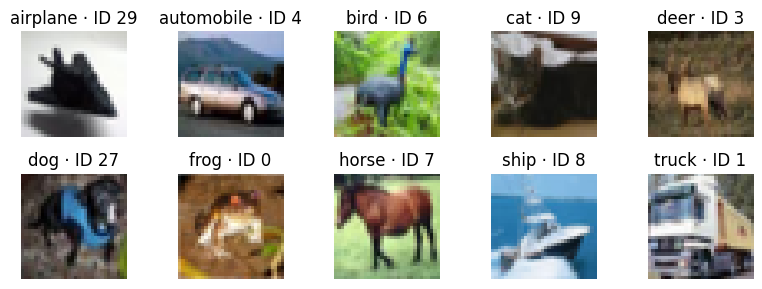

In [8]:
fig, axes = plt.subplots(2, 5, figsize=(8, 3))

for target, ax in enumerate(axes.flat):
    image_id = int(np.flatnonzero(labels == target)[0])
    ax.imshow(train_data.data[image_id], interpolation="nearest") # show the original pixels without smoothing
    ax.set_title(f"{class_names[target]} · ID {image_id}")
    ax.axis("off")

fig.tight_layout()
plt.show()

In [9]:
print("Images:", train_data.data.shape, train_data.data.dtype) # (N,H,W,C),
print("Pixel range:", train_data.data.min(), train_data.data.max())
display(pd.DataFrame({"class": class_names,"count": np.bincount(labels)}))

Images: (50000, 32, 32, 3) uint8
Pixel range: 0 255


,class,count
0,airplane,5000
1,automobile,5000
2,bird,5000
3,cat,5000
4,deer,5000
5,dog,5000
6,frog,5000
7,horse,5000
8,ship,5000
9,truck,5000


- Balanced dataset as same number for all

- Split into train and validation

In [ ]:
from sklearn.model_selection import train_test_split

train_test_split(test_size=0.1,random_state=239,shuffle=True,stratify=labels)